In [ ]:
import sqlite3
import pandas as pd

conn = sqlite3.connect(":memory:")
conn.execute("PRAGMA foreign_keys = ON;")
cur = conn.cursor()

1.MEMBUAT TIGA TABEL

In [ ]:
cur.executescript("""
DROP TABLE IF EXISTS peminjaman;
DROP TABLE IF EXISTS anggota;
DROP TABLE IF EXISTS buku;

CREATE TABLE buku (
    id      INTEGER PRIMARY KEY,
    judul   TEXT NOT NULL,
    penulis TEXT NOT NULL,
    tahun   INTEGER
);

CREATE TABLE anggota (
    id    INTEGER PRIMARY KEY,
    nama  TEXT NOT NULL,
    email TEXT UNIQUE
);

CREATE TABLE peminjaman (
    id          INTEGER PRIMARY KEY,
    id_anggota  INTEGER NOT NULL,
    id_buku     INTEGER NOT NULL,
    tgl_pinjam  TEXT NOT NULL,
    tgl_kembali TEXT,
    FOREIGN KEY (id_anggota) REFERENCES anggota(id),
    FOREIGN KEY (id_buku)    REFERENCES buku(id)
);
""")

A. DATA BUKU (Teknik Informatika) DAN ANGGOTA

In [ ]:
data_buku = [
    (1, "Introduction to Algorithms",                 "Thomas H. Cormen",     2009),
    (2, "Clean Code",                                 "Robert C. Martin",     2008),
    (3, "Database System Concepts",                   "Abraham Silberschatz", 2019),
    (4, "Computer Networking: A Top-Down Approach",   "James F. Kurose",      2021),
    (5, "Artificial Intelligence: A Modern Approach", "Stuart Russell",       2020),
]
cur.executemany("INSERT INTO buku VALUES (?, ?, ?, ?)", data_buku)

data_anggota = [
    (1, "Agus Salim",    "agus.salim@email.com"),
    (2, "Roy",           "roy@email.com"),
    (3, "Erwin Chanigo", "erwin.chanigo@email.com"),
    (4, "Een",           "een@email.com"),
    (5, "Erna",          "erna@email.com"),
]
cur.executemany("INSERT INTO anggota VALUES (?, ?, ?)", data_anggota)
conn.commit()
print("Data buku dan anggota berhasil ditambahkan.")

Data buku dan anggota berhasil ditambahkan.


# B.TRANSAKSI PEMINJAMAN (1 belum dikembalikan)

In [ ]:
data_pinjam = [
    (1, 1, 1, "2025-01-05", "2025-01-12"),
    (2, 1, 3, "2025-01-15", "2025-01-22"),
    (3, 2, 2, "2025-02-01", "2025-02-08"),
    (4, 3, 5, "2025-02-10", None),   # belum dikembalikan (NULL)
]
cur.executemany("INSERT INTO peminjaman VALUES (?, ?, ?, ?, ?)", data_pinjam)
conn.commit()
print("Data peminjaman berhasil ditambahkan.")


Data peminjaman berhasil ditambahkan.


C. DAFTAR PEMINJAMAN LENGKAP

In [ ]:
import pandas as pd

query_join = """
SELECT  p.id AS id_peminjaman,
        a.nama AS nama_anggota,
        b.judul AS judul_buku,
        p.tgl_pinjam,
        COALESCE(p.tgl_kembali, 'Belum dikembalikan') AS tgl_kembali
FROM peminjaman p
JOIN anggota a ON p.id_anggota = a.id
JOIN buku    b ON p.id_buku    = b.id
ORDER BY p.id;
"""
display(pd.read_sql_query(query_join, conn))

,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali
0,1,Agus Salim,Introduction to Algorithms,2025-01-05,2025-01-12
1,2,Agus Salim,Database System Concepts,2025-01-15,2025-01-22
2,3,Roy,Clean Code,2025-02-01,2025-02-08
3,4,Erwin Chanigo,Artificial Intelligence: A Modern Approach,2025-02-10,Belum dikembalikan


D.TOTAL BUKU DIPINJAM PER ANGGOTA

In [ ]:
query_group = """
SELECT  a.nama,
        COUNT(p.id) AS total_buku_dipinjam
FROM anggota a
LEFT JOIN peminjaman p ON a.id = p.id_anggota
GROUP BY a.id, a.nama
ORDER BY total_buku_dipinjam DESC, a.id;
"""
display(pd.read_sql_query(query_group, conn))

,nama,total_buku_dipinjam
0,Agus Salim,2
1,Roy,1
2,Erwin Chanigo,1
3,Een,0
4,Erna,0


SOAL NO 2


DataFrame dari query 1c (daftar peminjaman lengkap)


In [31]:
import pandas as pd

query_1c = """
SELECT  p.id AS id_peminjaman,
        a.nama AS nama_anggota,
        b.judul AS judul_buku,
        p.tgl_pinjam,
        p.tgl_kembali
FROM peminjaman p
JOIN anggota a ON p.id_anggota = a.id
JOIN buku    b ON p.id_buku    = b.id
ORDER BY p.id;
"""
df_peminjaman = pd.read_sql_query(query_1c, conn)

# Ubah kolom tanggal dari teks menjadi tipe datetime (NULL menjadi NaT)
df_peminjaman["tgl_pinjam"]  = pd.to_datetime(df_peminjaman["tgl_pinjam"])
df_peminjaman["tgl_kembali"] = pd.to_datetime(df_peminjaman["tgl_kembali"])

print("=== DataFrame dari Query 1c ===")
display(df_peminjaman)
print("\nUkuran (baris, kolom):", df_peminjaman.shape)
print("\nTipe data kolom:")
print(df_peminjaman.dtypes)

=== DataFrame dari Query 1c ===


,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali
0,1,Agus Salim,Introduction to Algorithms,2025-01-05,2025-01-12
1,2,Agus Salim,Database System Concepts,2025-01-15,2025-01-22
2,3,Roy,Clean Code,2025-02-01,2025-02-08
3,4,Erwin Chanigo,Artificial Intelligence: A Modern Approach,2025-02-10,NaT



Ukuran (baris, kolom): (4, 5)

Tipe data kolom:
id_peminjaman             int64
nama_anggota             object
judul_buku               object
tgl_pinjam       datetime64[ns]
tgl_kembali      datetime64[ns]
dtype: object


DataFrame dari query 1d (total buku per anggota)

In [32]:
query_1d = """
SELECT  a.nama,
        COUNT(p.id) AS total_buku_dipinjam
FROM anggota a
LEFT JOIN peminjaman p ON a.id = p.id_anggota
GROUP BY a.id, a.nama
ORDER BY total_buku_dipinjam DESC, a.id;
"""
df_total = pd.read_sql_query(query_1d, conn)

print("=== DataFrame dari Query 1d ===")
display(df_total)
print("\nUkuran (baris, kolom):", df_total.shape)

=== DataFrame dari Query 1d ===


,nama,total_buku_dipinjam
0,Agus Salim,2
1,Roy,1
2,Erwin Chanigo,1
3,Een,0
4,Erna,0



Ukuran (baris, kolom): (5, 2)


b. Lakukan eksplorasi data sederhana, seperti menghitung durasi peminjaman (dalam hari)

Hitung durasi peminjaman

In [33]:
df = df_peminjaman.copy()

# Durasi = tanggal kembali - tanggal pinjam (dalam hari)
# Hasilnya NaN jika buku belum dikembalikan (tgl_kembali = NULL)
df["durasi_hari"] = (df["tgl_kembali"] - df["tgl_pinjam"]).dt.days

display(df[["id_peminjaman", "nama_anggota", "judul_buku",
            "tgl_pinjam", "tgl_kembali", "durasi_hari"]])

,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali,durasi_hari
0,1,Agus Salim,Introduction to Algorithms,2025-01-05,2025-01-12,7.0
1,2,Agus Salim,Database System Concepts,2025-01-15,2025-01-22,7.0
2,3,Roy,Clean Code,2025-02-01,2025-02-08,7.0
3,4,Erwin Chanigo,Artificial Intelligence: A Modern Approach,2025-02-10,NaT,NaN


Statistik durasi

In [34]:
print("=== Statistik Durasi Peminjaman (hari) ===")
print(df["durasi_hari"].describe())

=== Statistik Durasi Peminjaman (hari) ===
count    3.0
mean     7.0
std      0.0
min      7.0
25%      7.0
50%      7.0
75%      7.0
max      7.0
Name: durasi_hari, dtype: float64


Hitung durasi untuk buku yang belum dikembalikan

In [35]:
hari_ini = pd.Timestamp.today().normalize()

df["durasi_sampai_sekarang"] = (df["tgl_kembali"].fillna(hari_ini) - df["tgl_pinjam"]).dt.days

display(df[["nama_anggota", "judul_buku", "durasi_hari", "durasi_sampai_sekarang"]])

,nama_anggota,judul_buku,durasi_hari,durasi_sampai_sekarang
0,Agus Salim,Introduction to Algorithms,7.0,7
1,Agus Salim,Database System Concepts,7.0,7
2,Roy,Clean Code,7.0,7
3,Erwin Chanigo,Artificial Intelligence: A Modern Approach,NaN,648


SOAL C


Import library

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

: Diagram batang jumlah buku dipinjam per anggota

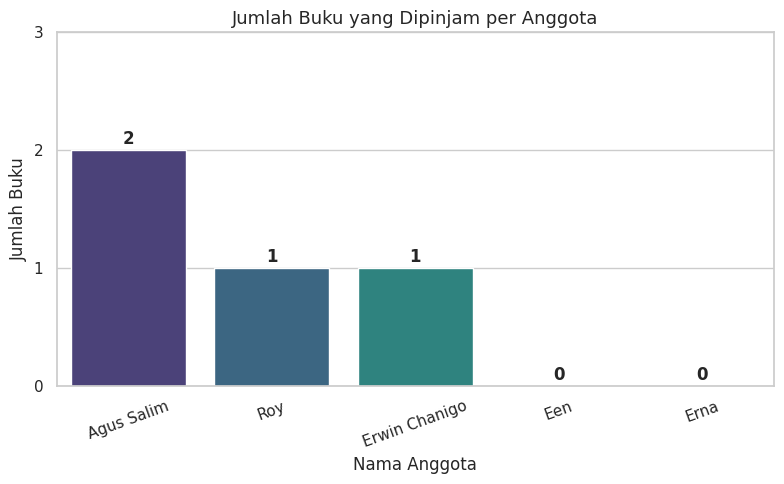

In [38]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(data=df_total, x="nama", y="total_buku_dipinjam",
                 hue="nama", palette="viridis", legend=False)

plt.title("Jumlah Buku yang Dipinjam per Anggota", fontsize=13)
plt.xlabel("Nama Anggota")
plt.ylabel("Jumlah Buku")
plt.yticks(range(0, int(df_total["total_buku_dipinjam"].max()) + 2))

# Tampilkan angka di atas batang
for i, v in enumerate(df_total["total_buku_dipinjam"]):
    ax.text(i, v + 0.05, str(v), ha="center", fontweight="bold")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Histogram durasi peminjaman

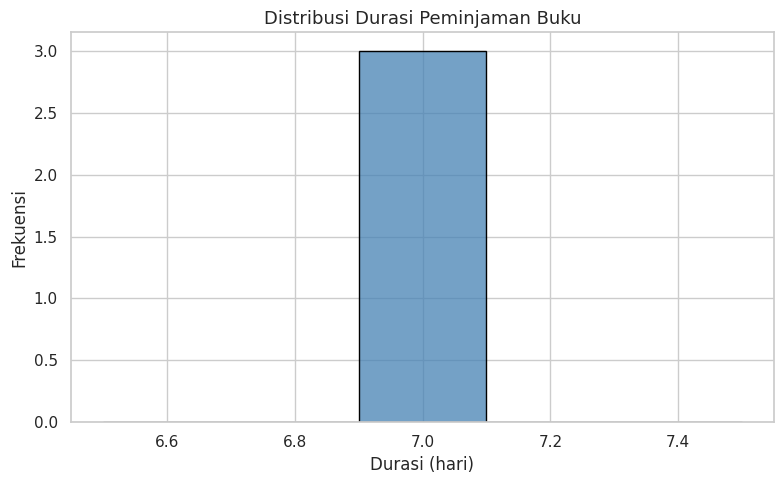

In [39]:
data_durasi = df.dropna(subset=["durasi_hari"])

plt.figure(figsize=(8, 5))
sns.histplot(data=data_durasi, x="durasi_hari", bins=5,
             color="steelblue", edgecolor="black")

plt.title("Distribusi Durasi Peminjaman Buku", fontsize=13)
plt.xlabel("Durasi (hari)")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

Diagram batang durasi per peminjaman


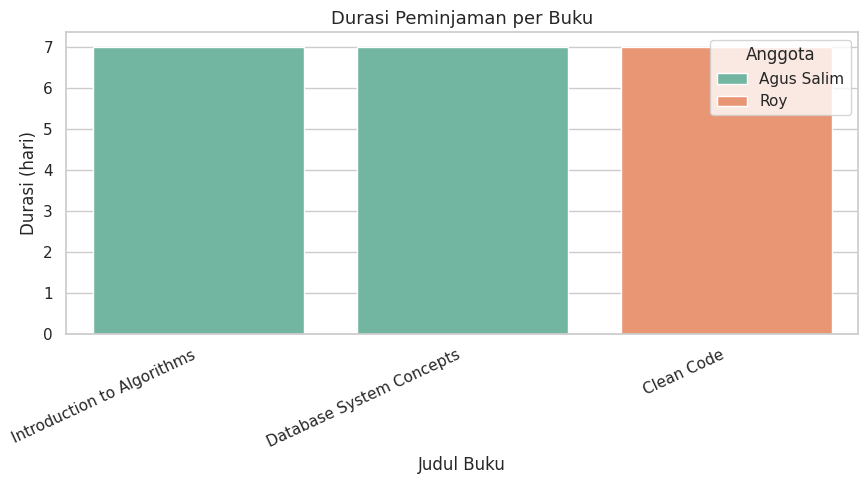

In [40]:
plt.figure(figsize=(9, 5))
ax = sns.barplot(data=data_durasi, x="judul_buku", y="durasi_hari",
                 hue="nama_anggota", dodge=False, palette="Set2")

plt.title("Durasi Peminjaman per Buku", fontsize=13)
plt.xlabel("Judul Buku")
plt.ylabel("Durasi (hari)")
plt.xticks(rotation=25, ha="right")
plt.legend(title="Anggota")
plt.tight_layout()
plt.show()